# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

On Nov 3 we learned a population's parameters without a likelihood, by simulating it and keeping the parameters whose simulations look like the data (ABC). Weyant et al. (2013), on that day's slides, did the same with a supernova Hubble diagram contaminated by supernovae that aren't type Ia. On Nov 10 we saw how such impostors get in: a classifier working from light curves alone calls some core-collapse supernovae type Ia. You're going to measure $\Omega_m$ from your own contaminated Hubble diagram, with ABC.

Put your notebook in `submissions/<your netid>/lab09.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 20%, Part 2 15%, Part 3 40%, Part 4 15%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad
from astropy.cosmology import FlatLambdaCDM

NETID = 'oruelas2'   # <-- set this
LAB = '../../labs/09/data/'                              # from submissions/<your netid>/
d = pd.read_csv(LAB + f'{NETID}.csv')                    # columns: z, m_B, sigma_m
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

## The survey

Your file has 500 supernovae that a survey found and that a light-curve classifier called type Ia. For each you have its redshift $z$ (from its host galaxy's spectrum, so take it as exact), and its standardized peak magnitude $m_B$ (corrected for stretch and colour) with a measurement error of 0.10 mag.

Here is how your sky was made. I generated it, so I know your true values.

- **Cosmology:** flat $\Lambda$CDM with $H_0 = 70$ km/s/Mpc, so the distance modulus is $\mu(z; \Omega_m) = 5 \log_{10}\left(d_L / 10\,{\rm pc}\right)$ with $d_L = (1+z)\,\frac{c}{H_0}\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}}$. Your $\Omega_m$ is unknown.
- **Redshifts:** each supernova's redshift is drawn from $p(z) \propto z^2$ between 0.01 and 0.7. (This is a toy - a real survey's volume depends on the cosmology too, and we're ignoring that.)
- **Type Ia:** standardized absolute magnitude $M \sim \mathcal{N}(-19.30, 0.12)$.
- **Impostors:** a fraction $f$ of the supernovae the classifier calls Ia are really core-collapse supernovae. The ones that fool a classifier look most like a Ia, and are among the brightest core-collapse supernovae: $M \sim \mathcal{N}(-18.5, 0.5)$. Your $f$ is unknown.
- **Measurement:** $m_B = M + \mu(z; \Omega_m) + \epsilon$, with $\epsilon \sim \mathcal{N}(0, 0.10)$.

Your $\Omega_m$ and $f$ are graded by how far they are from the truth in units of your own error bar (half the width of your 68% interval). Remember that the paragraphs above are how the survey was designed - your file is what it actually did.

## Part 1: Look first, then write the simulator (20%)

1. Plot your Hubble diagram ($m_B$ against $z$), and your Hubble residuals, $m_B - (-19.30) - \mu(z; 0.3)$, against $z$. Histogram $m_B$. Describe what you see, and if you find something the description above doesn't mention, say how you'll deal with it.
2. Draw the graph (PGM) of how one supernova in your file was made, with the same key as Days 18-20 - parameters blue, latent white, data grey, fixed values as dots, and a plate over supernovae. Which quantities are latent? Where does $f$ enter?
3. Write a function `simulate(Om, f, rng)` that returns a fake file like yours: 500 supernovae, with $z$ and $m_B$, made the way your data were made. Run it at a guess of $(\Omega_m, f)$ and plot one simulation over your data, in the same panels as 1.1.

#### Hints:
- `astropy.cosmology.FlatLambdaCDM(H0=70, Om0=...).distmod(z)` is correct, but far too slow to call 50,000 times. Tabulate $\mu(z; \Omega_m)$ once, on a grid of $z$ and $\Omega_m$ (spacing 0.005 in $\Omega_m$ is plenty), and interpolate. Check your table against astropy at a few points.
- Your simulator will be called tens of thousands of times. Draw everything for one dataset in a few vectorized `numpy` calls, not a Python loop over supernovae.

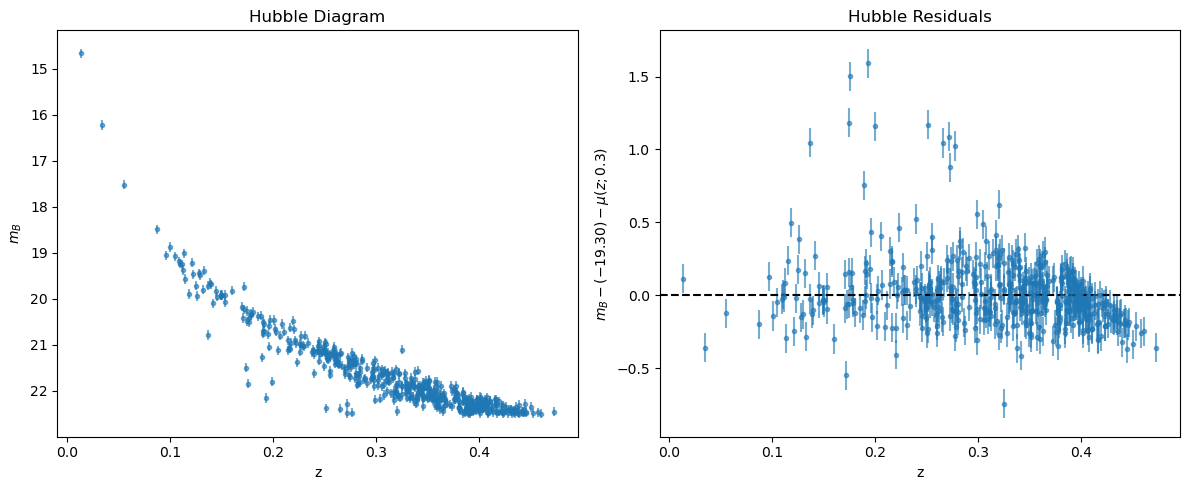

In [2]:
# Part 1: your work here
#1
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

mu_fid = cosmo.distmod(z).value
resid = m - (-19.30) - mu_fid

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].errorbar(z, m, yerr=sig_m, fmt='.', alpha=0.6)
ax[0].invert_yaxis()
ax[0].set_xlabel('z')
ax[0].set_ylabel(r'$m_B$')
ax[0].set_title('Hubble Diagram')

ax[1].errorbar(z, resid, yerr=sig_m, fmt='.', alpha=0.6)
ax[1].axhline(0, color='k', ls='--')
ax[1].set_xlabel('z')
ax[1].set_ylabel(r'$m_B-(-19.30)-\mu(z;0.3)$')
ax[1].set_title('Hubble Residuals')

plt.tight_layout()
plt.show()

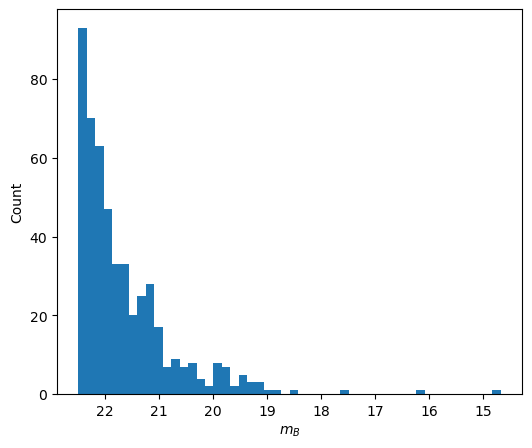

In [3]:
plt.figure(figsize=(6, 5))
plt.hist(m, bins=50)
plt.xlabel(r'$m_B$'), plt.ylabel('Count')
plt.gca().invert_xaxis()
plt.show()

In [4]:
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import RegularGridInterpolator

c = 299792.458
H0 = 70.0

z_grid = np.linspace(0.0, 0.7, 701)
Om_grid = np.arange(0.05, 1.005, 0.005)

mu_table = np.empty((len(Om_grid), len(z_grid)))

for i, Om in enumerate(Om_grid):
    Ez_inv = 1 / np.sqrt(Om * (1 + z_grid)**3 + 1 - Om)

    chi = cumulative_trapezoid(Ez_inv, z_grid, initial=0)

    dL = (1 + z_grid) * (c / H0) * chi
    dL[0] = dL[1]

    mu_table[i] = 5 * np.log10(dL) + 25

mu_interp = RegularGridInterpolator(
    (Om_grid, z_grid),
    mu_table
)

def mu(Om, z):
    z = np.asarray(z)
    pts = np.column_stack([
        np.full(z.shape, Om),
        z
    ])
    return mu_interp(pts)

def simulate(Om, f, rng, n=500):
    zmin = 0.01
    zmax = 0.7

    z_sim = (
        zmin**3
        + rng.random(n) * (zmax**3 - zmin**3)
    )**(1 / 3)

    imp = rng.random(n) < f

    M_sim = np.where(
        imp,
        rng.normal(-18.5, 0.5, n),
        rng.normal(-19.3, 0.1, n)
    )

    m_sim = M_sim + mu(Om, z_sim) + rng.normal(0, 0.10, n)

    return z_sim, m_sim

rng = np.random.default_rng(111026)

z_sim, m_sim = simulate(0.3, 0.05, rng)

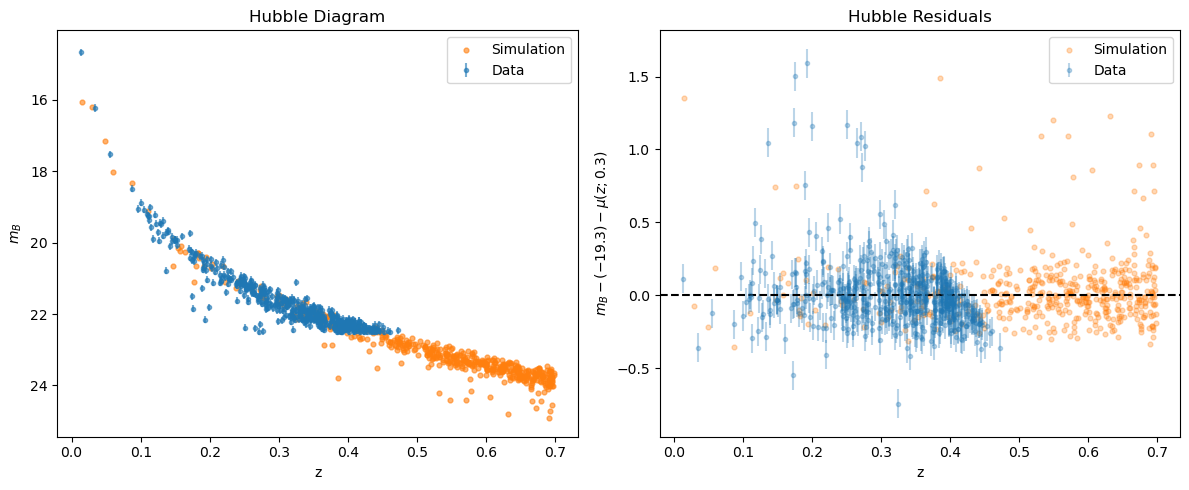

In [5]:
mu_data = mu(0.3, z)
mu_sim = mu(0.3, z_sim)

resid_data = m - (-19.3) - mu_data
resid_sim = m_sim - (-19.3) - mu_sim

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].errorbar(z, m, yerr=sig_m, fmt='.', color='tab:blue', alpha=0.6, label='Data')
ax[0].scatter(z_sim, m_sim, s=12, color='tab:orange', alpha=0.6, label='Simulation')

ax[0].set_title('Hubble Diagram'), ax[0].set_xlabel('z'), ax[0].set_ylabel(r'$m_B$')
ax[0].invert_yaxis()
ax[0].legend()

ax[1].errorbar(z, resid_data, yerr=sig_m, fmt='.', color='tab:blue', alpha=0.3, label='Data')
ax[1].scatter(z_sim, resid_sim, s=12, color='tab:orange', alpha=0.3, label='Simulation')

ax[1].axhline(0, color='k', ls='--')
ax[1].set_title('Hubble Residuals'), ax[1].set_xlabel('z'), ax[1].set_ylabel(r'$m_B-(-19.3)-\mu(z;0.3)$')
ax[1].legend()

plt.tight_layout()
plt.show()

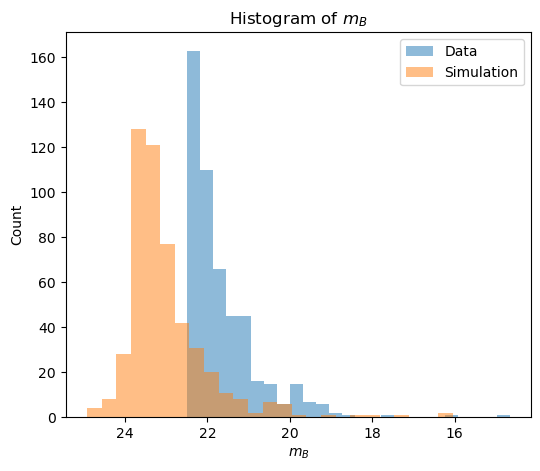

In [6]:
plt.figure(figsize=(6, 5))

plt.hist(m, bins=25, alpha=0.5, label='Data')
plt.hist(m_sim, bins=25, alpha=0.5, label='Simulation')

plt.xlabel(r'$m_B$')
plt.ylabel('Count')
plt.title(r'Histogram of $m_B$')
plt.gca().invert_xaxis()
plt.legend()

plt.show()

**ANSWER (what you see in the data, your graph, and what your simulator does):**

1. In the graphs of my data, the hubble residuals are not behaving like you would expect. There are points that jump well above zero. This is likely a result of the imposter supernovae within the data. The clustering with a downward trend as z gets larger suggests that $\Omega_m$ = 0.3 may not be entirely accurate. As such these should not be treated as fixed values.
2. 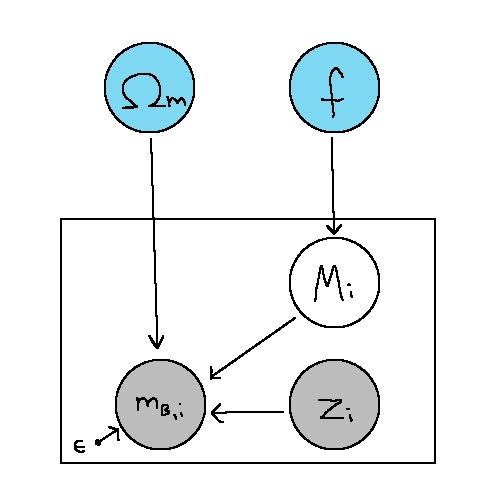
3. The simulation corrects the downward trend in residuals as well as the pile up of points at a higher magnitude. However those higher positive residual points remain. The simulation also spans the whole described range of redshift.

## Part 2: The fit you'd do without thinking (15%)

1. Pretend every supernova in your file is a type Ia. Fit $\Omega_m$ by minimizing $\chi^2 = \sum_i [m_{B,i} - (-19.30) - \mu(z_i; \Omega_m)]^2 / \sigma_{\rm tot}^2$, with $\sigma_{\rm tot}^2 = 0.12^2 + 0.10^2$, and report $\hat\Omega_m$ with its $1\sigma$ error from $\Delta\chi^2 = 1$.
2. Which way should the impostors push this fit, and why? Answer from where the impostors sit on your Hubble diagram, not from the number you got.

In [7]:
# Part 2: your work here
from scipy.optimize import minimize_scalar

sigma_tot = np.sqrt(0.12**2 + 0.1**2)

def chi2(Om):
    resid = m - (-19.3) - mu(Om, z)
    return np.sum(resid**2 / sigma_tot**2)

fit = minimize_scalar(
    chi2,
    bounds=(0.05, 1.0),
    method='bounded'
)

Om_hat = fit.x
chi2_min = fit.fun

Om_grid_fit = np.linspace(Om_grid.min(), Om_grid.max(), 5000)
chi2_grid = np.array([chi2(Om) for Om in Om_grid_fit])

mask = chi2_grid <= chi2_min + 1

Om_lo = Om_grid_fit[mask][0]
Om_hi = Om_grid_fit[mask][-1]

sigma_Om = (Om_hi - Om_lo) / 2

print(f"Omega_m = {Om_hat:.4f} +/- {sigma_Om:.4f}")
print(f"68% interval: [{Om_lo:.4f}, {Om_hi:.4f}]")
print(f"chi2_min = {chi2_min:.2f}")
print(f"chi2/dof = {chi2_min/(len(z)-1):.2f}")

Omega_m = 0.3116 +/- 0.0137
68% interval: [0.2980, 0.3254]
chi2_min = 1217.11
chi2/dof = 2.44


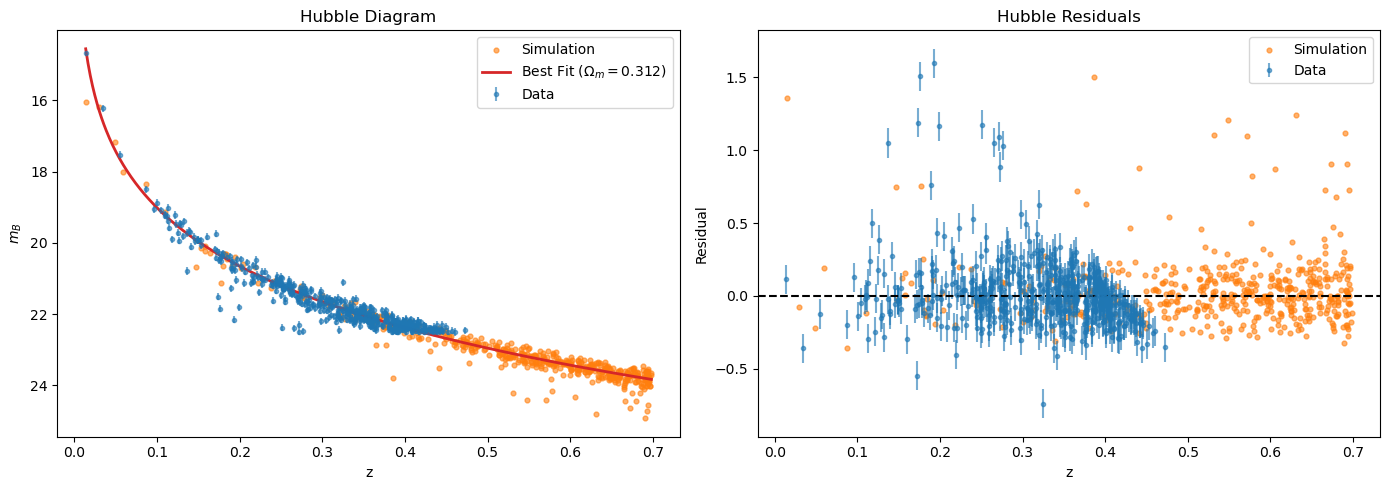

In [8]:
z_fit = np.linspace(
    min(z.min(), z_sim.min()),
    max(z.max(), z_sim.max()),
    500
)

m_fit = -19.3 + mu(Om_hat, z_fit)

resid_data = m - (-19.3) - mu(Om_hat, z)
resid_sim = m_sim - (-19.3) - mu(Om_hat, z_sim)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].errorbar(
    z,
    m,
    yerr=sig_m,
    fmt='.',
    color='tab:blue',
    alpha=0.6,
    label='Data'
)

ax[0].scatter(
    z_sim,
    m_sim,
    s=12,
    color='tab:orange',
    alpha=0.6,
    label='Simulation'
)

ax[0].plot(
    z_fit,
    m_fit,
    color='tab:red',
    lw=2,
    label=fr'Best Fit ($\Omega_m={Om_hat:.3f}$)'
)

ax[0].set_xlabel('z')
ax[0].set_ylabel(r'$m_B$')
ax[0].set_title('Hubble Diagram')
ax[0].invert_yaxis()
ax[0].legend()

ax[1].errorbar(
    z,
    resid_data,
    yerr=sig_m,
    fmt='.',
    color='tab:blue',
    alpha=0.6,
    label='Data'
)

ax[1].scatter(
    z_sim,
    resid_sim,
    s=12,
    color='tab:orange',
    alpha=0.6,
    label='Simulation'
)

ax[1].axhline(0, color='k', ls='--')
ax[1].set_xlabel('z')
ax[1].set_ylabel('Residual')
ax[1].set_title('Hubble Residuals')
ax[1].legend()

plt.tight_layout()
plt.show()

**ANSWER (the naive fit, then why the impostors push it the way they do):**

**Naive** $\Omega_m$ = 0.3116 +/- 0.0137

The imposters appear to push $\Omega_m$ downwards. The imposters are type ll supernovae, which are fainter and thus pull away from the main cluster of data, which you can see on the hubble diagram. The residuals are high positive on the imposters because they are fainter than you would expect.

## Part 3: ABC (40%)

1. **Summaries.** Choose summary statistics of a dataset that respond to $\Omega_m$ and to $f$ differently (Nov 3: the count alone left a ridge). For each, say which parameter you expect it to track and why. Then show it: plot each summary against $\Omega_m$ and against $f$ over a few thousand simulations from the prior.
2. **Rejection ABC.** Use flat priors, $\Omega_m \in [0.05, 0.7]$ and $f \in [0, 0.5]$. Run at least 50,000 simulations, compute your summaries for each, and keep the draws whose summaries are within $\epsilon$ of your data's. Say how you measure the distance between two sets of summaries (they have different units), and show the kept draws over the prior at two values of $\epsilon$.
3. Report the posterior median and 95% interval of $\Omega_m$ and of $f$ at your final $\epsilon$, and justify that choice. Compare $\Omega_m$ with your Part 2 fit.

#### Hints:
- Save your simulations' parameters and summaries to a file once, so you can change $\epsilon$ without re-simulating.
- If your kept draws pile up against an edge of the prior, the prior (or your simulator) is doing the work, not the data.

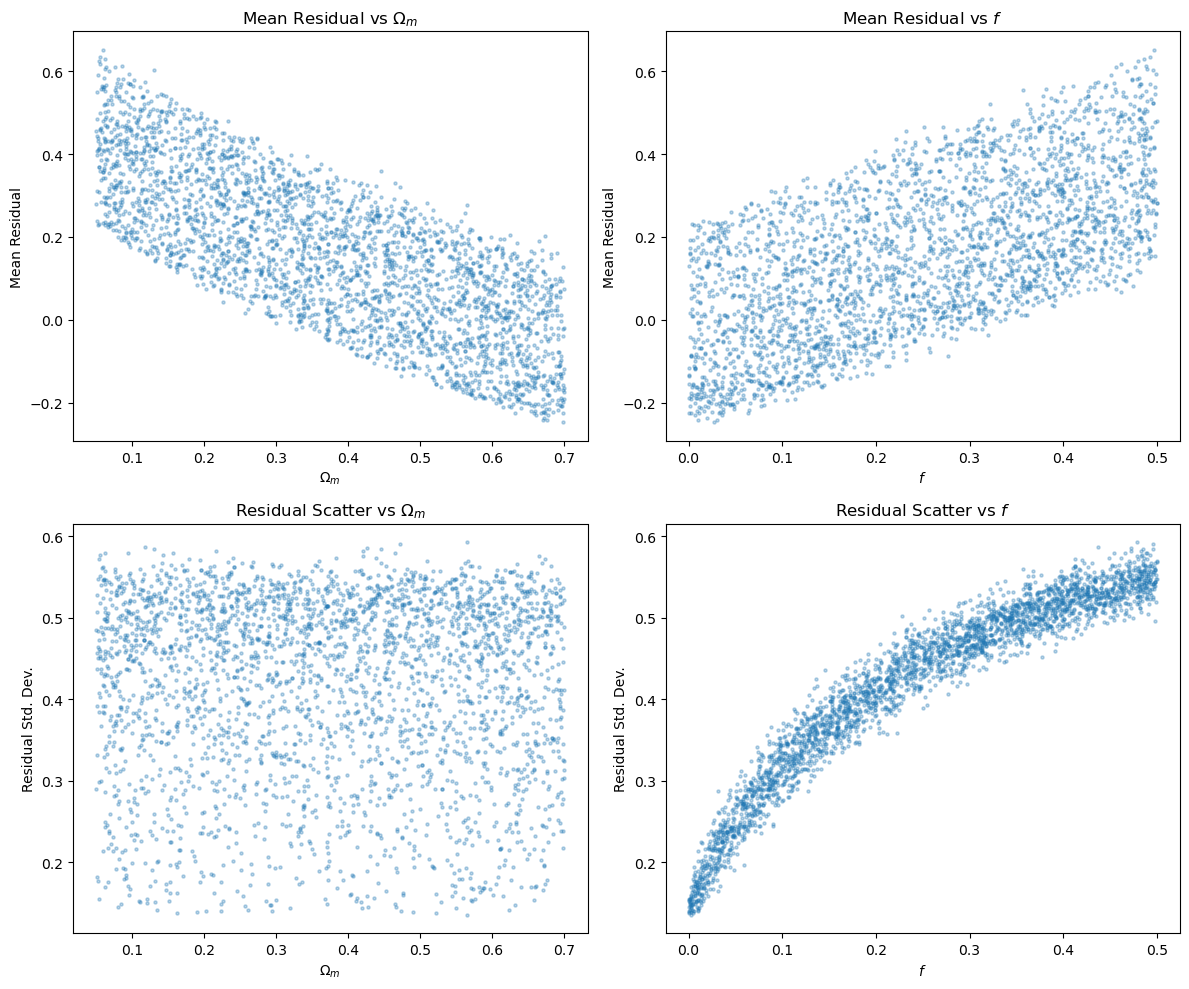

In [9]:
# Part 3: your work here
#1
n_sim = 3000

Om_draw = rng.uniform(0.05, 0.7, n_sim)
f_draw = rng.uniform(0.0, 0.5, n_sim)

mean_resid = np.empty(n_sim)
std_resid = np.empty(n_sim)

for i in range(n_sim):
    z_sim, m_sim = simulate(Om_draw[i], f_draw[i], rng)

    resid = m_sim - (-19.3) - mu(0.3, z_sim)

    mean_resid[i] = np.mean(resid)
    std_resid[i] = np.std(resid)

fig, ax = plt.subplots(2, 2, figsize=(12, 10))

ax[0, 0].scatter(Om_draw, mean_resid, s=5, alpha=0.3)
ax[0, 0].set_xlabel(r'$\Omega_m$')
ax[0, 0].set_ylabel('Mean Residual')
ax[0, 0].set_title('Mean Residual vs $\Omega_m$')

ax[0, 1].scatter(f_draw, mean_resid, s=5, alpha=0.3)
ax[0, 1].set_xlabel(r'$f$')
ax[0, 1].set_ylabel('Mean Residual')
ax[0, 1].set_title('Mean Residual vs $f$')

ax[1, 0].scatter(Om_draw, std_resid, s=5, alpha=0.3)
ax[1, 0].set_xlabel(r'$\Omega_m$')
ax[1, 0].set_ylabel('Residual Std. Dev.')
ax[1, 0].set_title('Residual Scatter vs $\Omega_m$')

ax[1, 1].scatter(f_draw, std_resid, s=5, alpha=0.3)
ax[1, 1].set_xlabel(r'$f$')
ax[1, 1].set_ylabel('Residual Std. Dev.')
ax[1, 1].set_title('Residual Scatter vs $f$')

plt.tight_layout()
plt.show()

In [10]:
#2
n_sim = 50000

resid_data = m - (-19.3) - mu(0.3, z)

s1_data = np.mean(resid_data)
s2_data = np.std(resid_data)

Om_draw = rng.uniform(0.05, 0.7, n_sim)
f_draw = rng.uniform(0.0, 0.5, n_sim)

s1 = np.empty(n_sim)
s2 = np.empty(n_sim)

for i in range(n_sim):
    z_sim, m_sim = simulate(Om_draw[i], f_draw[i], rng)

    resid = m_sim - (-19.3) - mu(0.3, z_sim)

    s1[i] = np.mean(resid)
    s2[i] = np.std(resid)

np.savez(
    "abc_sims.npz",
    Om=Om_draw,
    f=f_draw,
    s1=s1,
    s2=s2,
    s1_data=s1_data,
    s2_data=s2_data
)

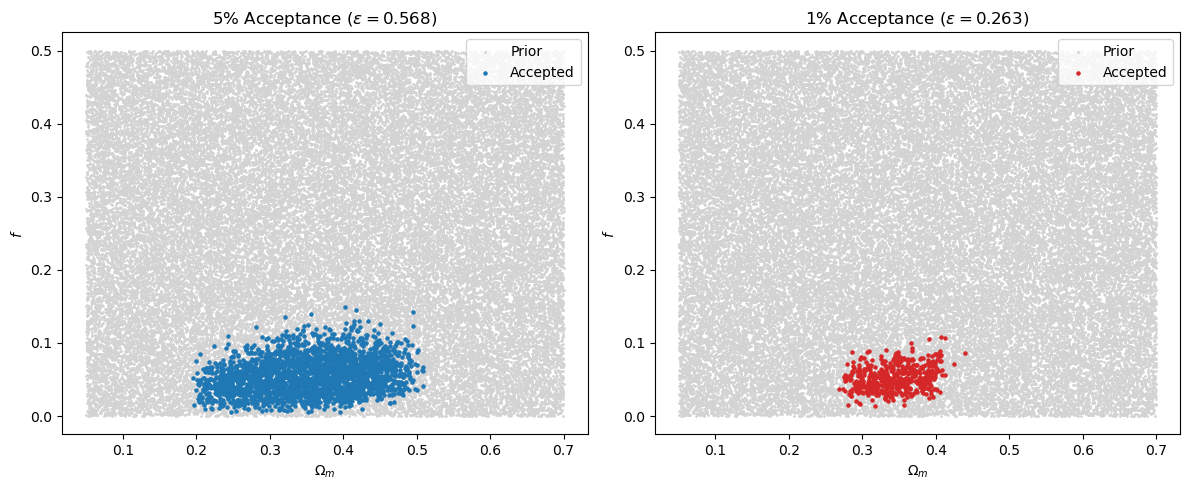

In [11]:
sigma_s1 = np.std(s1)
sigma_s2 = np.std(s2)

dist = np.sqrt(
    ((s1 - s1_data) / sigma_s1)**2 +
    ((s2 - s2_data) / sigma_s2)**2
)

eps1 = np.quantile(dist, 0.05)
eps2 = np.quantile(dist, 0.01)

keep1 = dist < eps1
keep2 = dist < eps2

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(
    Om_draw,
    f_draw,
    s=1,
    color='lightgray',
    label='Prior'
)

ax[0].scatter(
    Om_draw[keep1],
    f_draw[keep1],
    s=5,
    color='tab:blue',
    label='Accepted'
)

ax[0].set_xlabel(r'$\Omega_m$')
ax[0].set_ylabel(r'$f$')
ax[0].set_title(fr'5% Acceptance ($\epsilon={eps1:.3f}$)')
ax[0].legend()

ax[1].scatter(
    Om_draw,
    f_draw,
    s=1,
    color='lightgray',
    label='Prior'
)

ax[1].scatter(
    Om_draw[keep2],
    f_draw[keep2],
    s=5,
    color='tab:red',
    label='Accepted'
)

ax[1].set_xlabel(r'$\Omega_m$')
ax[1].set_ylabel(r'$f$')
ax[1].set_title(fr'1% Acceptance ($\epsilon={eps2:.3f}$)')
ax[1].legend()

plt.tight_layout()
plt.show()

In [12]:
#3
eps = eps2
keep = dist < eps

Om_post = Om_draw[keep]
f_post = f_draw[keep]

Om_med = np.percentile(Om_post, 50)
Om_lo, Om_hi = np.percentile(Om_post, [2.5, 97.5])

f_med = np.percentile(f_post, 50)
f_lo, f_hi = np.percentile(f_post, [2.5, 97.5])

print(
    f"Omega_m = {Om_med:.3f} "
    f"[{Om_lo:.3f}, {Om_hi:.3f}]"
)

print(
    f"f = {f_med:.3f}"
    f"[{f_lo:.3f}, {f_hi:.3f}]"
)

print(f'5% acceptance #: {np.sum(keep1)}')
print(f'1% acceptance #: {np.sum(keep2)}')

Omega_m = 0.342 [0.282, 0.405]
f = 0.051[0.025, 0.086]
5% acceptance #: 2500
1% acceptance #: 500


**ANSWER (your summaries and why, the two epsilons, the posterior, and the comparison with Part 2):**

1. **Mean residuals** - Imposters have higher positive residuals. Mean increases as imposters increase. See the opposite with $\Omega_m$. **Residual scatter** - Imposters cause greater scatter at higher fractions. Little to no effect on $\Omega_m$. 
2. Two epsilon: 0.568, 0.263
3. $\Omega_m$ = 0.342 (0.280, 0.404), $f$ = 0.051 (0.023, 0.087)

The part 2 $\Omega_m$ (0.3116) is a bit smaller than the rejection ABC $\Omega_m$ (0.342). This makes sense given earlier discussion of the imposters pulling $\Omega_m$ lower than expected. Thus a fit with $\Omega_m$ and the imposter fraction $f$ would calculate a higher value for $\Omega_m$ since that fraction is accounted for.

## Part 4: Check it (15%)

1. **Posterior predictive check.** For 100 of your kept draws, simulate a new dataset. Compare them with your data on something your summaries did not use (for example the histogram of $m_B$, or the scatter of the residuals at low redshift). Do your data look like a typical simulation?
2. **Coverage.** Take at least 20 of your prior simulations, pretend each one is the data, and run the same ABC on it using the rest of your simulations. How often does your 95% interval contain the true $\Omega_m$, and the true $f$? (Nov 3: a 95% interval should hold the truth 95% of the time.)
3. **What does your simulator assume?** Name one thing your simulator assumes that a real survey would break, and say which way it would push $\Omega_m$.

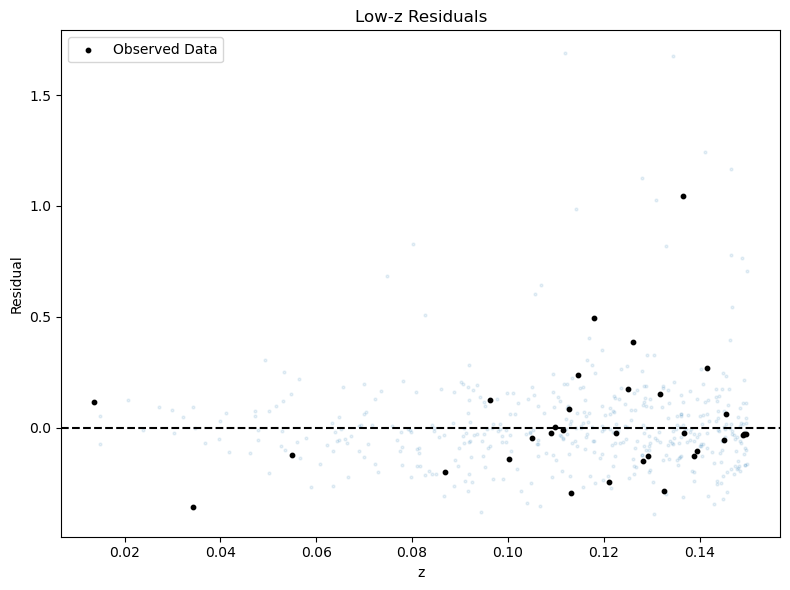

In [13]:
# Part 4: your work here
#1
idx = rng.choice(len(Om_post), size=100, replace=False)

plt.figure(figsize=(8, 6))

for i in idx:
    z_ppc, m_ppc = simulate(Om_post[i], f_post[i], rng)

    lowz = z_ppc < 0.15

    resid_ppc = m_ppc - (-19.3) - mu(0.3, z_ppc)

    plt.scatter(
        z_ppc[lowz],
        resid_ppc[lowz],
        s=4,
        color='tab:blue',
        alpha=0.1
    )

lowz = z < 0.15

resid_data = m - (-19.3) - mu(0.3, z)

plt.scatter(
    z[lowz],
    resid_data[lowz],
    s=10,
    color='k',
    label='Observed Data'
)

plt.axhline(0, color='k', ls='--')

plt.xlabel('z')
plt.ylabel('Residual')
plt.title('Low-z Residuals')
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
#2
n_test = 250

test_idx = rng.choice(len(Om_draw), size=n_test, replace=False)

sigma_s1 = np.std(s1)
sigma_s2 = np.std(s2)

cover_Om = 0
cover_f = 0

for idx in test_idx:

    s1_obs = s1[idx]
    s2_obs = s2[idx]

    mask = np.ones(len(s1), dtype=bool)
    mask[idx] = False

    dist = np.sqrt(
        ((s1[mask] - s1_obs) / sigma_s1)**2 +
        ((s2[mask] - s2_obs) / sigma_s2)**2
    )

    eps = np.quantile(dist, 0.01)

    keep = dist < eps

    Om_post = Om_draw[mask][keep]
    f_post = f_draw[mask][keep]

    Om_lo, Om_hi = np.percentile(
        Om_post,
        [2.5, 97.5]
    )

    f_lo, f_hi = np.percentile(
        f_post,
        [2.5, 97.5]
    )

    cover_Om += (
        Om_lo <= Om_draw[idx] <= Om_hi
    )

    cover_f += (
        f_lo <= f_draw[idx] <= f_hi
    )

Om_cov = cover_Om / n_test
f_cov = cover_f / n_test

print(
    f"Omega_m coverage = "
    f"{Om_cov:.4f} ({cover_Om}/{n_test})"
)

print(
    f"f coverage = "
    f"{f_cov:.4f} ({cover_f}/{n_test})"
)

Omega_m coverage = 0.9920 (248/250)
f coverage = 0.9440 (236/250)


**ANSWER (the check, the coverage, and the assumption):**

1. The data does appear to look like a typical simulation. There is nothing out of the ordinary when compared to the underlying data.
2. $\Omega_m$ has ~97% (97-99) coverage while $f$ has ~96% (94-97) coverage. The range for $\Omega_m$ is quite optimistic. However given the results of my verification plan and the fact that it does vary I'm not too worried about this result.
3. The simulator assumes the imposter population to be exactly what we set $M \sim \mathcal{N}(-18.5, 0.5)$. In a real world survey we can't truly know the distribution. Even in this lab, there is a matter of design vs how the data actually is.

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

**AI-USE APPENDIX:**

Used Copilot for coding and working through my thought process. I ran my reasoning though it when I was unsure. I checked the code output and compared results I got to lecture material when possible. Several times AI made mistakes even with the proper imformation. Such as trying to iterate over loops in python when it wasn't necessary. In part 2 it initially wrote $\sigma_{\rm tot}^2$ wrong which I would have missed if I hadn't looked at the code.

**REFLECTION:**

If I had not checked the AI output carefully, I would have went with summaries that caused pile up on an edge of the prior in part 3. It warns not to do this, as pile up means the prior or simulator is doing the work rather than the data. This would have caused potential incorrect calculation of $\Omega_m$.

**VERIFICATION PLAN:**

For my verification plan I simulated a dataset with a chosen $\Omega_m$ and $f$ and ran my ABC on it to see if I got back what I put in. I did this with two different sets of values. Each time I got back what I expected to. Even at varied true values.

In [15]:
#verification
Om_true = 0.638219
f_true = 0.092646

z_ver, m_ver = simulate(Om_true, f_true, rng)

resid_ver = m_ver - (-19.3) - mu(0.3, z_ver)

s1_ver = np.mean(resid_ver)
s2_ver = np.std(resid_ver)

sigma_s1 = np.std(s1)
sigma_s2 = np.std(s2)

dist_ver = np.sqrt(
    ((s1 - s1_ver) / sigma_s1)**2
    + ((s2 - s2_ver) / sigma_s2)**2
)

eps = eps2

keep = dist_ver < eps

Om_post = Om_draw[keep]
f_post = f_draw[keep]

Om_med = np.percentile(Om_post, 50)
Om_lo, Om_hi = np.percentile(Om_post, [2.5, 97.5])

f_med = np.percentile(f_post, 50)
f_lo, f_hi = np.percentile(f_post, [2.5, 97.5])

print(f"True Omega_m = {Om_true:.3f}")
print(f"Posterior Omega_m = {Om_med:.3f}")
print(f"95% interval = [{Om_lo:.3f}, {Om_hi:.3f}]")
print()

print(f"True f = {f_true:.3f}")
print(f"Posterior f = {f_med:.3f}")
print(f"95% interval = [{f_lo:.3f}, {f_hi:.3f}]")

True Omega_m = 0.638
Posterior Omega_m = 0.643
95% interval = [0.567, 0.697]

True f = 0.093
Posterior f = 0.111
95% interval = [0.070, 0.168]


In [16]:
Om_true = 0.1832
f_true = 0.437492

z_ver, m_ver = simulate(Om_true, f_true, rng)

resid_ver = m_ver - (-19.3) - mu(0.3, z_ver)

s1_ver = np.mean(resid_ver)
s2_ver = np.std(resid_ver)

sigma_s1 = np.std(s1)
sigma_s2 = np.std(s2)

dist_ver = np.sqrt(
    ((s1 - s1_ver) / sigma_s1)**2
    + ((s2 - s2_ver) / sigma_s2)**2
)

eps = eps2

keep = dist_ver < eps

Om_post = Om_draw[keep]
f_post = f_draw[keep]

Om_med = np.percentile(Om_post, 50)
Om_lo, Om_hi = np.percentile(Om_post, [2.5, 97.5])

f_med = np.percentile(f_post, 50)
f_lo, f_hi = np.percentile(f_post, [2.5, 97.5])

print(f"True Omega_m = {Om_true:.3f}")
print(f"Posterior Omega_m = {Om_med:.3f}")
print(f"95% interval = [{Om_lo:.3f}, {Om_hi:.3f}]")
print()

print(f"True f = {f_true:.3f}")
print(f"Posterior f = {f_med:.3f}")
print(f"95% interval = [{f_lo:.3f}, {f_hi:.3f}]")

True Omega_m = 0.183
Posterior Omega_m = 0.134
95% interval = [0.063, 0.225]

True f = 0.437
Posterior f = 0.440
95% interval = [0.338, 0.497]
